In [1]:
#1
!pip install -q timm h5py opencv-python-headless

import os, glob, time, random
import numpy as np, cv2, h5py, timm
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as T
import matplotlib.pyplot as plt

def set_seed(s=0):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(0)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True
print(device, torch.__version__, timm.__version__)

cuda 2.14.1+cu130 1.0.31


In [6]:
#2
import subprocess
from huggingface_hub import HfApi, hf_hub_download

REPO     = 'sayakpaul/nyu_depth_v2'
NYU_ROOT = '/content/data/nyudepthv2'
TMP      = '/content/hf_tmp'
os.makedirs(NYU_ROOT, exist_ok=True)

shards = sorted(f for f in HfApi().list_repo_files(REPO, repo_type='dataset')
                if f.startswith('data/') and f.endswith('.tar'))
print(len(shards), 'shards:', shards)

for fn in shards:
    marker = os.path.join(NYU_ROOT, '.done_' + os.path.basename(fn))
    if os.path.exists(marker):
        continue
    p = hf_hub_download(REPO, fn, repo_type='dataset', local_dir=TMP)
    subprocess.run(['tar', '-xf', p, '-C', NYU_ROOT], check=True)
    os.remove(p)
    open(marker, 'w').close()
    print('done', fn)

# Verify
for sp in ['train', 'val']:
    fs = [f for f in glob.glob(os.path.join(NYU_ROOT, '**', '*.h5'), recursive=True)
          if f'{os.sep}{sp}{os.sep}' in f]
    print(sp, len(fs), 'files', '| e.g.', fs[0] if fs else None)

14 shards: ['data/train-000000.tar', 'data/train-000001.tar', 'data/train-000002.tar', 'data/train-000003.tar', 'data/train-000004.tar', 'data/train-000005.tar', 'data/train-000006.tar', 'data/train-000007.tar', 'data/train-000008.tar', 'data/train-000009.tar', 'data/train-000010.tar', 'data/train-000011.tar', 'data/val-000000.tar', 'data/val-000001.tar']


data/train-000000.tar: reconstructing file:   0%|          |  0.00B / 3.00GB            

data/train-000000.tar: downloading bytes:           |  0.00B            

done data/train-000000.tar


data/train-000001.tar: reconstructing file:   0%|          |  0.00B / 3.00GB            

data/train-000001.tar: downloading bytes:           |  0.00B            

... (33 outputs left out)

done data/val-000000.tar


data/val-000001.tar: reconstructing file:   0%|          |  0.00B / 14.8MB            

data/val-000001.tar: downloading bytes:           |  0.00B            

done data/val-000001.tar
train 47584 files | e.g. /content/data/nyudepthv2/train/classroom_0011/00371.h5
val 654 files | e.g. /content/data/nyudepthv2/val/official/00679.h5


In [7]:
#3
class NYUDepthV2(Dataset):

    IH, IW = 480, 640

    def __init__(self, root, split, train, out_size=(224, 224)):
        all_h5 = glob.glob(os.path.join(root, '**', '*.h5'), recursive=True)
        self.files = sorted(f for f in all_h5 if f'{os.sep}{split}{os.sep}' in f)
        assert len(self.files) > 0, f'no h5 files for split {split} under {root}'
        self.train, self.out_size = train, out_size
        self.jitter = T.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4)

    def __len__(self):
        return len(self.files)

    @staticmethod
    def _scale(img, s, interp):
        h, w = img.shape[:2]
        return cv2.resize(img, (int(round(w * s)), int(round(h * s))), interpolation=interp)

    @staticmethod
    def _rotate(img, angle, interp):
        h, w = img.shape[:2]
        M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
        return cv2.warpAffine(img, M, (w, h), flags=interp, borderValue=0)

    @staticmethod
    def _center_crop(img, ch, cw):
        h, w = img.shape[:2]
        t, l = (h - ch) // 2, (w - cw) // 2
        return img[t:t + ch, l:l + cw]

    def __getitem__(self, i):
        with h5py.File(self.files[i], 'r') as f:
            rgb = np.transpose(np.array(f['rgb']), (1, 2, 0))      # HxWx3 uint8
            depth = np.array(f['depth'], dtype=np.float32)          # HxW, meters

        if self.train:
            s = np.random.uniform(1.0, 1.5)
            angle = np.random.uniform(-5.0, 5.0)
            flip = np.random.uniform() < 0.5
            base = 250.0 / self.IH
            depth = depth / s
        else:
            s, angle, flip, base = 1.0, 0.0, False, 240.0 / self.IH

        def tf(img, interp):
            img = self._scale(img, base, interp)
            if self.train:
                img = self._rotate(img, angle, interp)
                img = self._scale(img, s, interp)
            img = self._center_crop(img, 228, 304)
            if flip:
                img = img[:, ::-1]
            return cv2.resize(np.ascontiguousarray(img),
                              (self.out_size[1], self.out_size[0]), interpolation=interp)

        rgb = tf(rgb, cv2.INTER_LINEAR)
        depth = tf(depth, cv2.INTER_NEAREST)   # nearest keeps invalid (0) pixels from blending

        if self.train:
            rgb = np.array(self.jitter(Image.fromarray(rgb)))

        rgb = torch.from_numpy(rgb).permute(2, 0, 1).float() / 255.0   # [0,1]; normalized inside the model
        depth = torch.from_numpy(np.ascontiguousarray(depth)).unsqueeze(0)
        return rgb, depth

In [24]:
#4
from multiprocessing import Pool

CACHE_DIR = '/content/cache'
os.makedirs(CACHE_DIR, exist_ok=True)
_CACHE_CFG = {}

def _load_resize(path, base):
    with h5py.File(path, 'r') as f:
        rgb = np.transpose(np.array(f['rgb']), (1, 2, 0))
        depth = np.array(f['depth'], dtype=np.float32)
    rgb = NYUDepthV2._scale(rgb, base, cv2.INTER_LINEAR)
    depth = NYUDepthV2._scale(depth, base, cv2.INTER_NEAREST)
    return rgb, depth

def _fill(job):
    tag, lo, hi = job
    c = _CACHE_CFG[tag]
    rgb_mm = np.load(c['rgb'], mmap_mode='r+')
    dep_mm = np.load(c['dep'], mmap_mode='r+')
    for i in range(lo, hi):
        r, d = _load_resize(c['files'][i], c['base'])
        rgb_mm[i] = r; dep_mm[i] = d
    rgb_mm.flush(); dep_mm.flush()
    return hi - lo

for split, base in [('val', 240.0 / 480), ('train', 250.0 / 480)]:
    files = sorted(f for f in glob.glob(os.path.join(NYU_ROOT, '**', '*.h5'), recursive=True)
                   if f'{os.sep}{split}{os.sep}' in f)
    r0, d0 = _load_resize(files[0], base)
    N = len(files)
    rgb_path, dep_path = f'{CACHE_DIR}/{split}_rgb.npy', f'{CACHE_DIR}/{split}_depth.npy'
    np.lib.format.open_memmap(rgb_path, mode='w+', dtype=np.uint8,   shape=(N, *r0.shape)).flush()
    np.lib.format.open_memmap(dep_path, mode='w+', dtype=np.float32, shape=(N, *d0.shape)).flush()
    _CACHE_CFG[split] = dict(files=files, base=base, rgb=rgb_path, dep=dep_path)
    jobs = [(split, lo, min(lo + 500, N)) for lo in range(0, N, 500)]
    done = 0
    with Pool(os.cpu_count()) as pool:
        for k in pool.imap_unordered(_fill, jobs):
            done += k
    print(split, N, 'cached', r0.shape, d0.shape)

val 654 cached (240, 320, 3) (240, 320)
train 47584 cached (250, 333, 3) (250, 333)


In [26]:
#5
class NYUCached(NYUDepthV2):
    """Same samples/augmentation as NYUDepthV2, reading the pre-resized cache instead of the h5 files."""
    def __init__(self, split, train, cache_dir=CACHE_DIR, out_size=(224, 224)):
        self.train, self.out_size = train, out_size
        self.jitter = T.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4)
        self.rgb = np.load(f'{cache_dir}/{split}_rgb.npy', mmap_mode='r')
        self.dep = np.load(f'{cache_dir}/{split}_depth.npy', mmap_mode='r')

    def __len__(self):
        return len(self.rgb)

    def __getitem__(self, i):
        rgb, depth = np.array(self.rgb[i]), np.array(self.dep[i])
        if self.train:
            s = np.random.uniform(1.0, 1.5)
            angle = np.random.uniform(-5.0, 5.0)
            flip = np.random.uniform() < 0.5
            depth = depth / s
        else:
            s, angle, flip = 1.0, 0.0, False

        def tf(img, interp):
            if self.train:
                img = self._rotate(img, angle, interp)
                img = self._scale(img, s, interp)
            img = self._center_crop(img, 228, 304)
            if flip:
                img = img[:, ::-1]
            return cv2.resize(np.ascontiguousarray(img),
                              (self.out_size[1], self.out_size[0]), interpolation=interp)

        rgb = tf(rgb, cv2.INTER_LINEAR)
        depth = tf(depth, cv2.INTER_NEAREST)
        if self.train:
            rgb = np.array(self.jitter(Image.fromarray(rgb)))
        rgb = torch.from_numpy(rgb).permute(2, 0, 1).float() / 255.0
        depth = torch.from_numpy(np.ascontiguousarray(depth)).unsqueeze(0)
        return rgb, depth

In [27]:
#6
def dw_sep_layer(in_c, out_c, k=5):
    """Depthwise k x k conv + pointwise 1x1 conv (depthwise decomposition), each with BN + ReLU."""
    return nn.Sequential(
        nn.Conv2d(in_c, in_c, k, 1, (k - 1) // 2, groups=in_c, bias=False),
        nn.BatchNorm2d(in_c), nn.ReLU(inplace=True),
        nn.Conv2d(in_c, out_c, 1, 1, 0, bias=False),
        nn.BatchNorm2d(out_c), nn.ReLU(inplace=True))


class FastDepth(nn.Module):
    def __init__(self, pretrained=True, k=5):
        super().__init__()
        # ---- Encoder: MobileNet (v1), ImageNet-pretrained, no avgpool / FC ----
        mb = timm.create_model('mobilenetv1_100', pretrained=pretrained)
        stem = [mb.conv_stem, mb.bn1]
        if hasattr(mb, 'act1'):          # older/newer timm versions may keep a separate activation
            stem.append(mb.act1)
        self.stem = nn.Sequential(*stem)  # MobileNet layer 0: 112x112x32  # MobileNet layer 0: 112x112x32
        self.stages = mb.blocks

        # ---- Decoder: NNConv5 (5 depthwise-separable layers, channels halve each time) ----
        self.dec1 = dw_sep_layer(1024, 512, k)
        self.dec2 = dw_sep_layer(512, 256, k)
        self.dec3 = dw_sep_layer(256, 128, k)
        self.dec4 = dw_sep_layer(128, 64, k)
        self.dec5 = dw_sep_layer(64, 32, k)
        # final pointwise layer -> 1-channel depth (BN+ReLU as in the released implementation)
        self.dec6 = nn.Sequential(nn.Conv2d(32, 1, 1, bias=False), nn.BatchNorm2d(1), nn.ReLU(inplace=True))
        self.up = nn.Upsample(scale_factor=2, mode='nearest')

        for m in [self.dec1, self.dec2, self.dec3, self.dec4, self.dec5, self.dec6]:
            for mod in m.modules():
                if isinstance(mod, nn.Conv2d):
                    n = mod.kernel_size[0] * mod.kernel_size[1] * mod.out_channels
                    mod.weight.data.normal_(0, (2.0 / n) ** 0.5)
                elif isinstance(mod, nn.BatchNorm2d):
                    mod.weight.data.fill_(1); mod.bias.data.zero_()

        self.register_buffer('mean', torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer('std',  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        x = (x - self.mean) / self.std
        x = self.stem(x)
        x = self.stages[0](x); s1 = x      # 112x112x64
        x = self.stages[1](x); s2 = x      # 56x56x128
        x = self.stages[2](x); s3 = x      # 28x28x256
        for i in range(3, len(self.stages)):
            x = self.stages[i](x)          # -> 7x7x1024          # -> 7x7x1024

        x = self.up(self.dec1(x))          # 14x14x512
        x = self.up(self.dec2(x)) + s3     # 28x28x256  (+ skip)
        x = self.up(self.dec3(x)) + s2     # 56x56x128  (+ skip)
        x = self.up(self.dec4(x)) + s1     # 112x112x64 (+ skip)
        x = self.up(self.dec5(x))          # 224x224x32
        return self.dec6(x)                # 224x224x1

In [28]:
#7
from torch.utils.flop_counter import FlopCounterMode

model = FastDepth(pretrained=True).eval()
x = torch.randn(1, 3, 224, 224)

# check encoder feature shapes (stem 112x112x32, skips 112x112x64 / 56x56x128 / 28x28x256, out 7x7x1024)
with torch.no_grad():
    h = model.stem(x); print('stem', tuple(h.shape))
    for i, st in enumerate(model.stages):
        h = st(h); print(f'stage{i}', tuple(h.shape))
    print('output', tuple(model(x).shape))

params = sum(p.numel() for p in model.parameters())
with FlopCounterMode(display=False) as fc:
    model(x)
print(f'weights: {params/1e6:.2f} M   (paper, unpruned w/ skip-add: 3.93 M)')
print(f'MACs:    {fc.get_total_flops()/2/1e9:.2f} G   (paper, unpruned w/ skip-add: 0.74 G)')

stem (1, 32, 112, 112)
stage0 (1, 64, 112, 112)
stage1 (1, 128, 56, 56)
stage2 (1, 256, 28, 28)
stage3 (1, 512, 14, 14)
stage4 (1, 1024, 7, 7)
output (1, 1, 224, 224)
weights: 3.96 M   (paper, unpruned w/ skip-add: 3.93 M)
MACs:    0.74 G   (paper, unpruned w/ skip-add: 0.74 G)


In [29]:
#8
def masked_l1(pred, target):
    valid = (target > 0).float()
    return ((pred - target).abs() * valid).sum() / valid.sum().clamp(min=1)

@torch.no_grad()
def batch_metrics(pred, target):
    """Per-image RMSE (m) and delta1 (max(pred/gt, gt/pred) < 1.25), averaged over the batch."""
    rmse, d1 = [], []
    for p, t in zip(pred, target):
        v = t > 0
        p, t = p[v].clamp(min=1e-3), t[v]
        rmse.append(torch.sqrt(((p - t) ** 2).mean()))
        d1.append((torch.max(p / t, t / p) < 1.25).float().mean())
    return torch.stack(rmse).mean().item(), torch.stack(d1).mean().item()

In [30]:
#9
CFG = dict(
    batch_size=8, lr=0.01, momentum=0.9, weight_decay=1e-4,
    epochs=20, lr_step=5, lr_gamma=0.1,
    num_workers=min(8, os.cpu_count()))

print('cpu cores:', os.cpu_count())

def _worker_init(_):
    cv2.setNumThreads(0)

train_ds = NYUCached('train', train=True)
val_ds   = NYUCached('val',   train=False)
train_loader = DataLoader(train_ds, batch_size=CFG['batch_size'], shuffle=True,
                          num_workers=CFG['num_workers'], pin_memory=True, drop_last=True,
                          persistent_workers=True, prefetch_factor=4, worker_init_fn=_worker_init)
val_loader   = DataLoader(val_ds, batch_size=1, shuffle=False, num_workers=2,
                          worker_init_fn=_worker_init)
print(len(train_ds), 'train /', len(val_ds), 'val')


model = FastDepth(pretrained=True).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=CFG['lr'], momentum=CFG['momentum'],
                            weight_decay=CFG['weight_decay'])
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=CFG['lr_step'], gamma=CFG['lr_gamma'])

cmodel = model  # used only for training; `model` (eager) is used for validation and saving

CKPT_DIR = '/content/ckpt'; os.makedirs(CKPT_DIR, exist_ok=True)

cpu cores: 12
47584 train / 654 val


In [31]:
#10
def train_one_epoch(epoch):
    model.train()
    total = torch.zeros((), device=device); n = 0; t0 = time.time()
    for it, (rgb, depth) in enumerate(train_loader):
        rgb = rgb.to(device, non_blocking=True)
        depth = depth.to(device, non_blocking=True)
        loss = masked_l1(cmodel(rgb), depth)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        total += loss.detach(); n += 1
        if (it + 1) % 500 == 0:
            print(f'  ep {epoch} it {it+1}/{len(train_loader)}  L1 {total.item()/n:.4f}  ({time.time()-t0:.0f}s)')
    return (total / n).item()

@torch.no_grad()
def validate(loader=None):
    model.eval()
    loader = loader or val_loader
    r, d, n = 0.0, 0.0, 0
    for rgb, depth in loader:
        rgb, depth = rgb.to(device), depth.to(device)
        rm, dl = batch_metrics(model(rgb), depth)
        r += rm * len(rgb); d += dl * len(rgb); n += len(rgb)
    return r / n, d / n

In [32]:
#11
import copy
# (a) data loader alone
it_ = iter(train_loader)
for _ in range(20): next(it_)                       # skip worker warm-up
t0 = time.time()
for _ in range(200): next(it_)
print(f'data only: {200/(time.time()-t0):.1f} it/s')

# (b) GPU step alone (fixed batch, forward+backward, eager vs compiled)
r, d = next(iter(train_loader)); r, d = r.to(device), d.to(device)
def gpu_speed(m, iters=100):
    m.train()
    for _ in range(5):
        masked_l1(m(r), d).backward()
    torch.cuda.synchronize(); t0 = time.time()
    for _ in range(iters):
        masked_l1(m(r), d).backward()
    torch.cuda.synchronize()
    return iters / (time.time() - t0)
bm = copy.deepcopy(model)
print(f'GPU eager:    {gpu_speed(bm):.1f} it/s')
print(f'GPU compiled: {gpu_speed(torch.compile(bm)):.1f} it/s')

data only: 26.2 it/s
GPU eager:    49.5 it/s
GPU compiled: 51.5 it/s


In [33]:
#12
best_d1 = 0.0
for epoch in range(1, CFG['epochs'] + 1):
    tr_loss = train_one_epoch(epoch)
    rmse, d1 = validate()
    scheduler.step()
    print(f'Epoch {epoch:02d} | lr {optimizer.param_groups[0]["lr"]:.5f} | train L1 {tr_loss:.4f} '
          f'| val RMSE {rmse:.3f} m | val delta1 {d1:.3f}')
    torch.save({'model': model.state_dict(), 'optimizer': optimizer.state_dict(),
                'epoch': epoch, 'rmse': rmse, 'delta1': d1}, f'{CKPT_DIR}/last.pth')
    if d1 > best_d1:
        best_d1 = d1
        torch.save(model.state_dict(), f'{CKPT_DIR}/best.pth')
print('best delta1:', best_d1, '(paper, unpruned: delta1 0.775, RMSE 0.599)')

  ep 1 it 500/5948  L1 0.9668  (16s)
  ep 1 it 1000/5948  L1 0.9079  (31s)
  ep 1 it 1500/5948  L1 0.8821  (44s)
  ep 1 it 2000/5948  L1 0.8656  (56s)
  ep 1 it 2500/5948  L1 0.8497  (68s)
  ep 1 it 3000/5948  L1 0.8349  (79s)
  ep 1 it 3500/5948  L1 0.8240  (90s)
  ep 1 it 4000/5948  L1 0.8113  (101s)
  ep 1 it 4500/5948  L1 0.8011  (113s)
  ep 1 it 5000/5948  L1 0.7897  (124s)
  ep 1 it 5500/5948  L1 0.7781  (135s)
Epoch 01 | lr 0.01000 | train L1 0.7686 | val RMSE 0.899 m | val delta1 0.523
  ep 2 it 500/5948  L1 0.6279  (11s)
  ep 2 it 1000/5948  L1 0.6176  (22s)
  ep 2 it 1500/5948  L1 0.6173  (33s)
  ep 2 it 2000/5948  L1 0.6107  (44s)
  ep 2 it 2500/5948  L1 0.6067  (55s)
  ep 2 it 3000/5948  L1 0.6011  (66s)
  ep 2 it 3500/5948  L1 0.5963  (76s)
  ep 2 it 4000/5948  L1 0.5932  (87s)
  ep 2 it 4500/5948  L1 0.5896  (99s)
  ep 2 it 5000/5948  L1 0.5847  (110s)
  ep 2 it 5500/5948  L1 0.5813  (121s)
Epoch 02 | lr 0.01000 | train L1 0.5780 | val RMSE 0.790 m | val delta1 0.603
  ep

In [35]:
#13
model.load_state_dict(torch.load(f'{CKPT_DIR}/best.pth', map_location=device))
rmse, d1 = validate()
print(f'Val: RMSE {rmse:.3f} m | delta1 {d1:.3f}')

@torch.no_grad()
def benchmark(m, dev, iters=200, warmup=30):
    m = m.to(dev).eval()
    x = torch.randn(1, 3, 224, 224, device=dev)
    for _ in range(warmup): m(x)
    if dev.type == 'cuda': torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(iters): m(x)
    if dev.type == 'cuda': torch.cuda.synchronize()
    ms = (time.time() - t0) / iters * 1000
    return ms, 1000 / ms

for dev in ([torch.device('cuda')] if torch.cuda.is_available() else []) + [torch.device('cpu')]:
    ms, fps = benchmark(model, dev, iters=200 if dev.type == 'cuda' else 30)
    print(f'{dev.type}: {ms:.2f} ms/img  ({fps:.1f} fps)')
model.to(device)

Val: RMSE 0.696 m | delta1 0.677
cuda: 4.71 ms/img  (212.5 fps)
cpu: 19.24 ms/img  (52.0 fps)


FastDepth(
  (stem): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (1): BatchNormAct2d(
      32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True
      (drop): Identity()
      (act): ReLU6(inplace=True)
    )
  )
  (stages): Sequential(
    (0): Sequential(
      (0): DepthwiseSeparableConv(
        (conv_dw): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
        (bn1): BatchNormAct2d(
          32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True
          (drop): Identity()
          (act): ReLU6(inplace=True)
        )
        (aa): Identity()
        (se): Identity()
        (conv_pw): Conv2d(32, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn2): BatchNormAct2d(
          64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True
          (drop): Identity()
          (act): ReLU6(inplace=True)
     

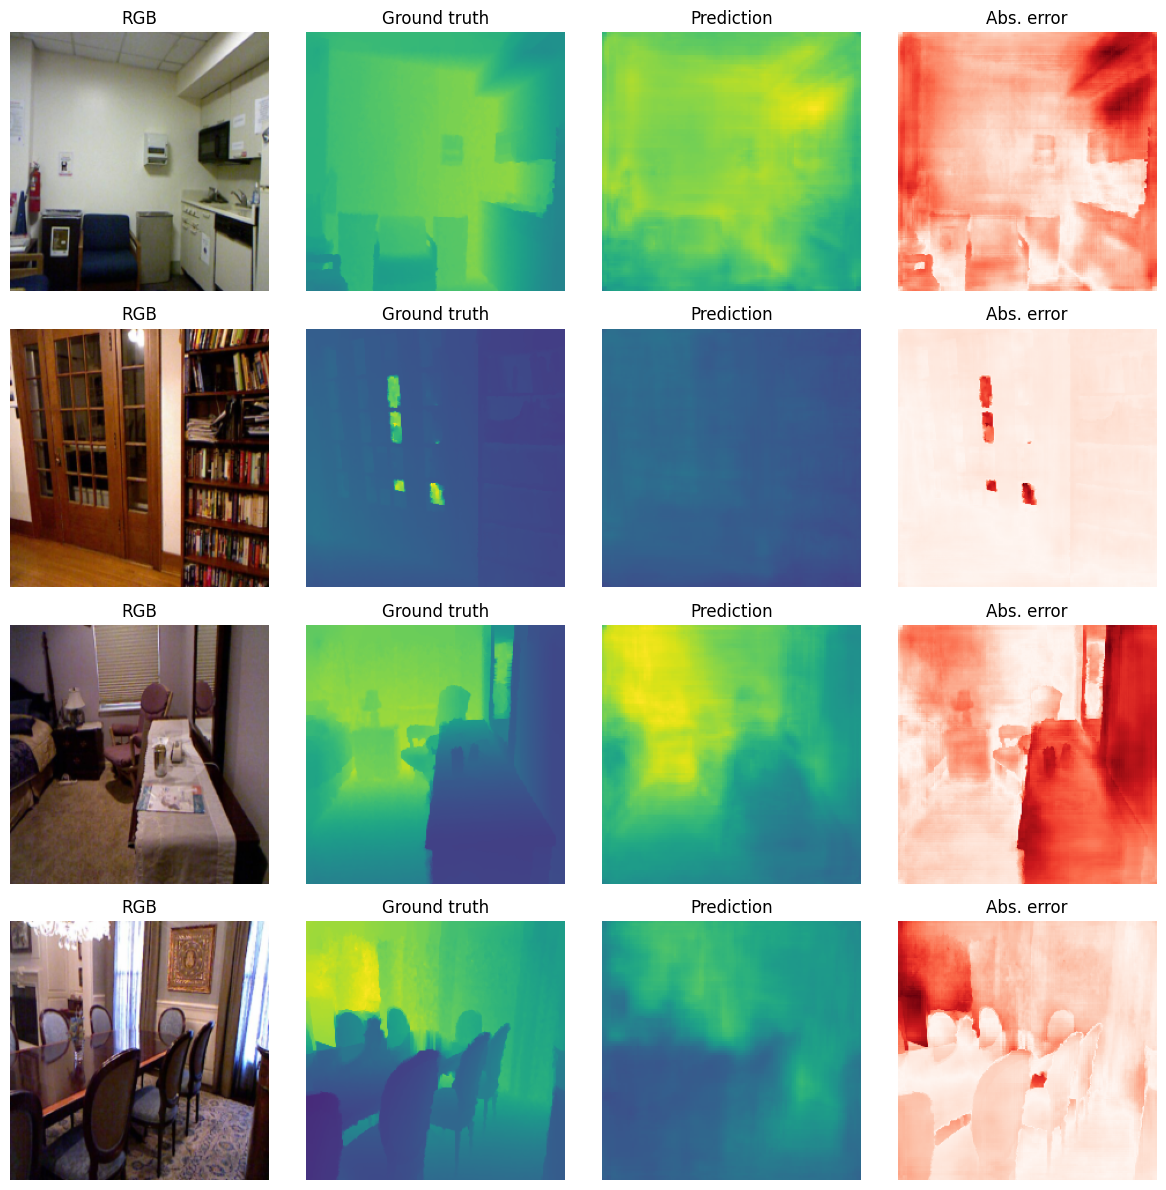

In [36]:
#14
model.eval()
idx = np.linspace(0, len(val_ds) - 1, 4).astype(int)
fig, ax = plt.subplots(len(idx), 4, figsize=(12, 3 * len(idx)))
with torch.no_grad():
    for r, i in enumerate(idx):
        rgb, gt = val_ds[i]
        pred = model(rgb.unsqueeze(0).to(device)).squeeze().cpu().numpy()
        gt = gt.squeeze().numpy()
        vmax = max(gt.max(), pred.max())
        err = np.abs(pred - gt) * (gt > 0)
        ax[r, 0].imshow(rgb.permute(1, 2, 0).numpy())
        ax[r, 1].imshow(gt,   cmap='viridis', vmin=0, vmax=vmax)
        ax[r, 2].imshow(pred, cmap='viridis', vmin=0, vmax=vmax)
        ax[r, 3].imshow(err,  cmap='Reds')
        for c, t in enumerate(['RGB', 'Ground truth', 'Prediction', 'Abs. error']):
            ax[r, c].set_title(t); ax[r, c].axis('off')
plt.tight_layout(); plt.show()

In [37]:
#15
from torch.utils.data import Subset

def recalibrate_bn(m, n_batches=1000, bs=8):
    """Re-estimate BN running stats (cumulative average) on un-augmented train images."""
    dl = DataLoader(NYUCached('train', train=False), batch_size=bs, shuffle=True,
                    num_workers=CFG['num_workers'], drop_last=True, worker_init_fn=_worker_init)
    bns = [mod for mod in m.modules() if isinstance(mod, nn.modules.batchnorm._BatchNorm)]
    old_mom = [b.momentum for b in bns]
    for b in bns:
        b.reset_running_stats(); b.momentum = None      # None = cumulative moving average
    m.train()
    with torch.no_grad():
        for i, (rgb, _) in enumerate(dl):
            if i >= n_batches: break
            m(rgb.to(device))
    for b, mo in zip(bns, old_mom):
        b.momentum = mo
    m.eval()

model.load_state_dict(torch.load(f'{CKPT_DIR}/last.pth')['model'])
print('val, as trained:       RMSE %.3f | d1 %.3f' % validate())
recalibrate_bn(model)
print('val, BN recalibrated:  RMSE %.3f | d1 %.3f' % validate())

sub = Subset(NYUCached('train', train=False), np.random.RandomState(0).choice(len(train_ds), 654, replace=False))
print('train subset, no aug:  RMSE %.3f | d1 %.3f' % validate(
    DataLoader(sub, batch_size=1, num_workers=2, worker_init_fn=_worker_init)))

val, as trained:       RMSE 0.708 | d1 0.673
val, BN recalibrated:  RMSE 0.880 | d1 0.519
train subset, no aug:  RMSE 0.641 | d1 0.698


In [38]:
#16
ck = torch.load(f'{CKPT_DIR}/last.pth')['model']   # reload: the in-memory model currently has recalibrated BN stats
model.load_state_dict(ck); model.eval()
print('as trained:               RMSE %.3f | d1 %.3f' % validate())

@torch.no_grad()
def eval_variants():
    model.eval()
    bn = model.dec6[1]
    res = {'final BN uses per-image stats': [0, 0, 0], 'per-image median-scaled': [0, 0, 0]}
    for rgb, depth in val_loader:
        rgb, depth = rgb.to(device), depth.to(device)
        bn.train(); mom = bn.momentum; bn.momentum = 0.0
        a = model(rgb); bn.eval(); bn.momentum = mom
        rm, dl = batch_metrics(a, depth)
        res['final BN uses per-image stats'][0] += rm; res['final BN uses per-image stats'][1] += dl
        p = model(rgb); t = depth
        v = t > 0
        p = p * (t[v].median() / p[v].median().clamp(min=1e-3))
        rm, dl = batch_metrics(p, t)
        res['per-image median-scaled'][0] += rm; res['per-image median-scaled'][1] += dl
        res['final BN uses per-image stats'][2] += 1
    n = res['final BN uses per-image stats'][2]
    for k, (r, d, _) in res.items():
        print(f'{k:30s} RMSE {r/n:.3f} | d1 {d/n:.3f}')
eval_variants()

as trained:               RMSE 0.708 | d1 0.673
final BN uses per-image stats  RMSE 1.072 | d1 0.399
per-image median-scaled        RMSE 0.612 | d1 0.759


In [39]:
#17
class FastDepthV2(FastDepth):
    """Same as FastDepth, except the final layer is a single pointwise conv (no BN/ReLU)."""
    def __init__(self, pretrained=True, k=5):
        super().__init__(pretrained, k)
        self.dec6 = nn.Conv2d(32, 1, kernel_size=1)
        nn.init.normal_(self.dec6.weight, 0, 0.01)   # my choice, not from the paper: start near typical NYU depth
        nn.init.constant_(self.dec6.bias, 2.5)

m_test = FastDepthV2(pretrained=True).eval()
x = torch.randn(1, 3, 224, 224)
with FlopCounterMode(display=False) as fc:
    out = m_test(x)
print('output', tuple(out.shape),
      '| weights %.2f M' % (sum(p.numel() for p in m_test.parameters()) / 1e6),
      '| MACs %.2f G' % (fc.get_total_flops() / 2 / 1e9))
del m_test

output (1, 1, 224, 224) | weights 3.96 M | MACs 0.74 G


In [46]:
#18
CFG2 = dict(
    batch_size=8, lr=0.01, momentum=0.9, weight_decay=1e-4,
    epochs=30, milestones=[20, 30], gamma=0.1)

CKPT_DIR_V2 = '/content/ckpt_v2'; os.makedirs(CKPT_DIR_V2, exist_ok=True)

set_seed(0)
model_v2 = FastDepthV2(pretrained=True).to(device)
for mod in model_v2.modules():                       # smoother BN running stats at batch size 8
    if isinstance(mod, nn.modules.batchnorm._BatchNorm):
        mod.momentum = 0.01

opt_v2 = torch.optim.SGD(model_v2.parameters(), lr=CFG2['lr'], momentum=CFG2['momentum'],
                         weight_decay=CFG2['weight_decay'])
sched_v2 = torch.optim.lr_scheduler.MultiStepLR(opt_v2, milestones=CFG2['milestones'], gamma=CFG2['gamma'])
history_v2 = []

In [47]:
#19
def train_epoch(m, opt, epoch, log_every=2000):
    m.train()
    total = torch.zeros((), device=device); n = 0; t0 = time.time()
    for it, (rgb, depth) in enumerate(train_loader):
        rgb, depth = rgb.to(device, non_blocking=True), depth.to(device, non_blocking=True)
        loss = masked_l1(m(rgb), depth)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        total += loss.detach(); n += 1
        if (it + 1) % log_every == 0:
            print(f'  ep {epoch} it {it+1}/{len(train_loader)}  L1 {total.item()/n:.4f}  ({time.time()-t0:.0f}s)')
    return (total / n).item()

@torch.no_grad()
def validate_model(m, loader=None):
    m.eval()
    loader = loader or val_loader
    r = d = 0.0; n = 0
    for rgb, depth in loader:
        rgb, depth = rgb.to(device), depth.to(device)
        rm, dl = batch_metrics(m(rgb), depth)
        r += rm * len(rgb); d += dl * len(rgb); n += len(rgb)
    return r / n, d / n

In [54]:
#20
CFG2['epochs'] = 40
print('finished epochs:', len(history_v2), '| will run', len(history_v2) + 1, 'to', CFG2['epochs'])

finished epochs: 30 | will run 31 to 40


In [55]:
#21
for epoch in range(len(history_v2) + 1, CFG2['epochs'] + 1):
    tr = train_epoch(model_v2, opt_v2, epoch)
    rmse, d1 = validate_model(model_v2)
    sched_v2.step()
    history_v2.append(dict(epoch=epoch, train_l1=tr, rmse=rmse, d1=d1))
    print(f'Epoch {epoch:02d} | lr {opt_v2.param_groups[0]["lr"]:.5f} | train L1 {tr:.4f} '
          f'| val RMSE {rmse:.3f} m | val delta1 {d1:.3f}')
    torch.save({'model': model_v2.state_dict(), 'opt': opt_v2.state_dict(),
                'sched': sched_v2.state_dict(), 'history': history_v2}, f'{CKPT_DIR_V2}/last.pth')
print(f'FINAL V2: RMSE {rmse:.3f} m | delta1 {d1:.3f}   (paper, unpruned: 0.599 / 0.775)')

  ep 31 it 2000/5948  L1 0.1385  (42s)
  ep 31 it 4000/5948  L1 0.1385  (83s)
Epoch 31 | lr 0.00010 | train L1 0.1386 | val RMSE 0.620 m | val delta1 0.737
  ep 32 it 2000/5948  L1 0.1385  (41s)
  ep 32 it 4000/5948  L1 0.1383  (82s)
Epoch 32 | lr 0.00010 | train L1 0.1383 | val RMSE 0.618 m | val delta1 0.738
  ep 33 it 2000/5948  L1 0.1389  (42s)
  ep 33 it 4000/5948  L1 0.1381  (84s)
Epoch 33 | lr 0.00010 | train L1 0.1383 | val RMSE 0.618 m | val delta1 0.738
  ep 34 it 2000/5948  L1 0.1376  (41s)
  ep 34 it 4000/5948  L1 0.1383  (82s)
Epoch 34 | lr 0.00010 | train L1 0.1378 | val RMSE 0.619 m | val delta1 0.737
  ep 35 it 2000/5948  L1 0.1375  (41s)
  ep 35 it 4000/5948  L1 0.1374  (82s)
Epoch 35 | lr 0.00010 | train L1 0.1376 | val RMSE 0.617 m | val delta1 0.738
  ep 36 it 2000/5948  L1 0.1366  (41s)
  ep 36 it 4000/5948  L1 0.1370  (82s)
Epoch 36 | lr 0.00010 | train L1 0.1372 | val RMSE 0.618 m | val delta1 0.738
  ep 37 it 2000/5948  L1 0.1386  (41s)
  ep 37 it 4000/5948  L1 

In [56]:
#22
@torch.no_grad()
def eval_median_scaled(m):
    """Diagnostic only (uses GT per image): error after removing per-image global scale."""
    m.eval(); r = d = 0.0; n = 0
    for rgb, depth in val_loader:
        rgb, depth = rgb.to(device), depth.to(device)
        p = m(rgb); v = depth > 0
        p = p * (depth[v].median() / p[v].median().clamp(min=1e-3))
        rm, dl = batch_metrics(p, depth); r += rm; d += dl; n += 1
    return r / n, d / n

baseline = FastDepth(pretrained=False).to(device)
baseline.load_state_dict(torch.load(f'{CKPT_DIR}/last.pth', map_location=device)['model'])
baseline.eval()

rows = [('Paper, unpruned (Table VII)', 0.599, 0.775, None, None),
        ('Baseline (final BN+ReLU, 20 ep)',) + validate_model(baseline) + eval_median_scaled(baseline),
        ('V2 (plain final conv, 40 ep)',)   + validate_model(model_v2)  + eval_median_scaled(model_v2)]
print(f'{"model":36s} {"RMSE":>6s} {"d1":>6s} | {"RMSE*":>6s} {"d1*":>6s}   (* median-scaled, diagnostic)')
for name, r, d, rs, ds in rows:
    extra = f'{rs:6.3f} {ds:6.3f}' if rs is not None else ''
    print(f'{name:36s} {r:6.3f} {d:6.3f} | {extra}')

model                                  RMSE     d1 |  RMSE*    d1*   (* median-scaled, diagnostic)
Paper, unpruned (Table VII)           0.599  0.775 | 
Baseline (final BN+ReLU, 20 ep)       0.708  0.673 |  0.612  0.759
V2 (plain final conv, 40 ep)          0.618  0.738 |  0.554  0.795


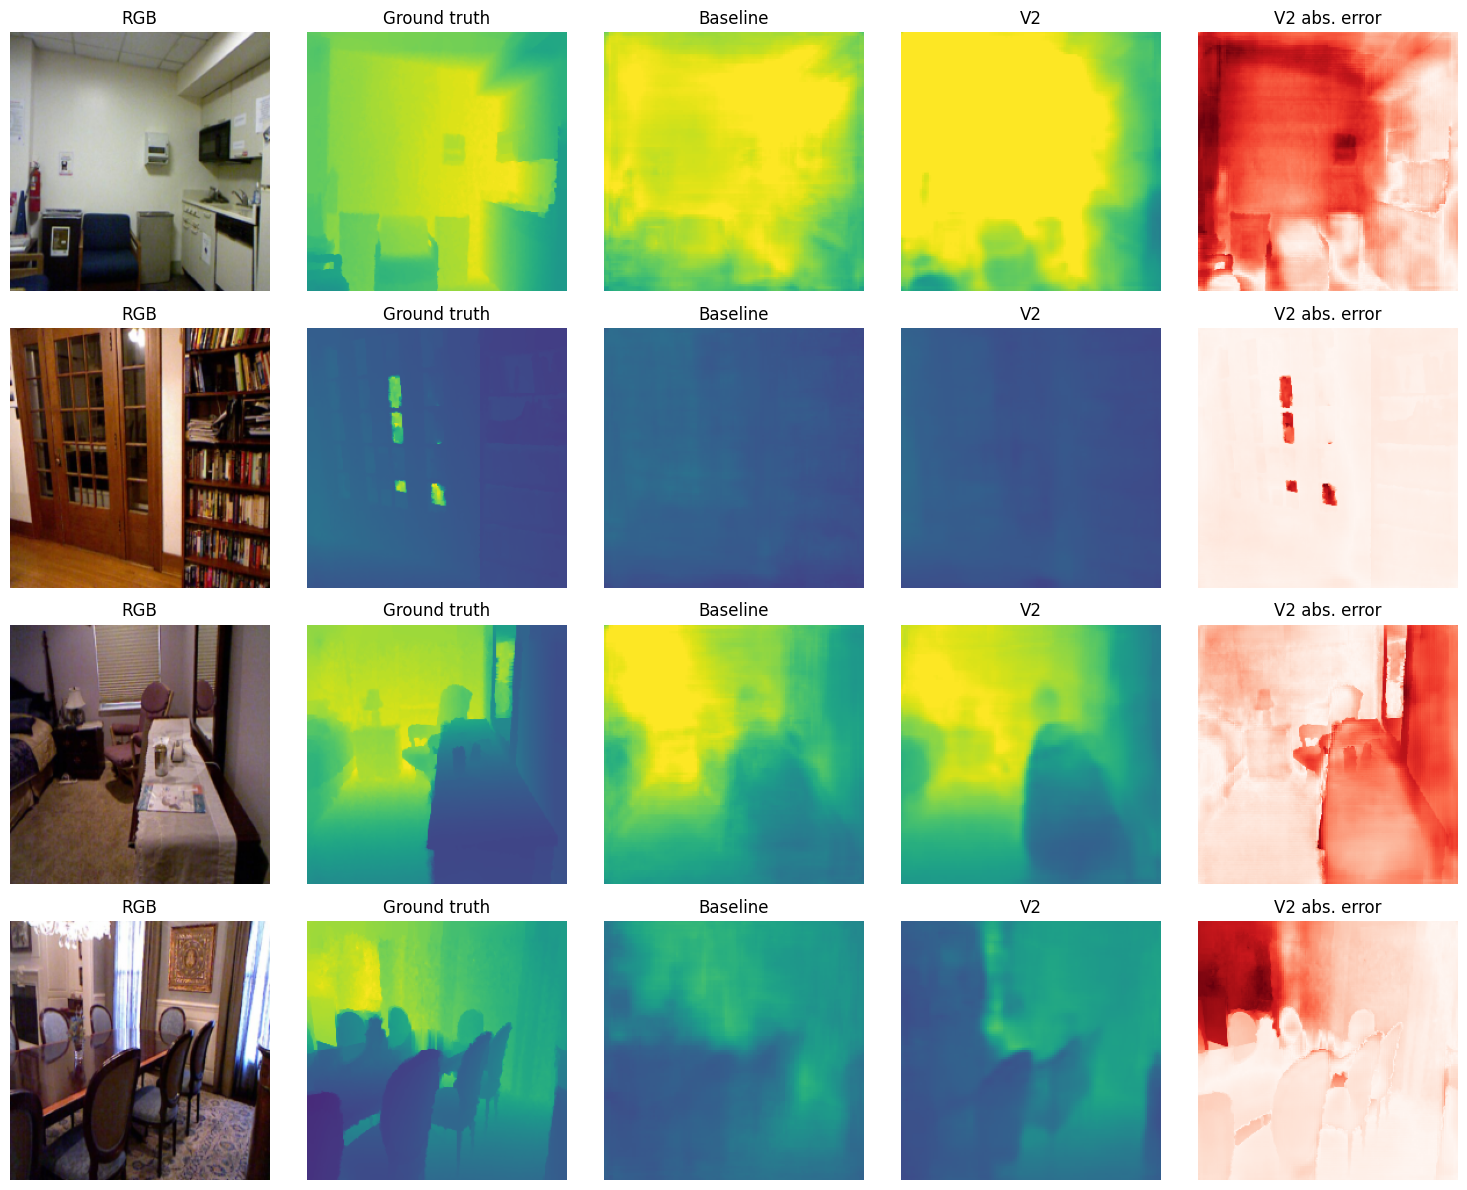

In [57]:
#23
idx = np.linspace(0, len(val_ds) - 1, 4).astype(int)
cols = ['RGB', 'Ground truth', 'Baseline', 'V2', 'V2 abs. error']
fig, ax = plt.subplots(len(idx), 5, figsize=(15, 3 * len(idx)))
with torch.no_grad():
    for r, i in enumerate(idx):
        rgb, gt = val_ds[i]
        x = rgb.unsqueeze(0).to(device)
        pb = baseline(x).squeeze().cpu().numpy()
        pv = model_v2.eval()(x).squeeze().cpu().numpy()
        gt = gt.squeeze().numpy()
        vmax = gt.max()
        imgs = [rgb.permute(1, 2, 0).numpy(), gt, pb, pv, np.abs(pv - gt) * (gt > 0)]
        for c, im in enumerate(imgs):
            ax[r, c].imshow(im, **({} if c == 0 else dict(cmap='Reds') if c == 4 else dict(cmap='viridis', vmin=0, vmax=vmax)))
            ax[r, c].set_title(cols[c]); ax[r, c].axis('off')
plt.tight_layout(); plt.show()

In [58]:
#24
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/fastdepth_v2 && cp /content/ckpt_v2/last.pth /content/drive/MyDrive/fastdepth_v2/

Mounted at /content/drive
